In [12]:
import numpy as np
import pandas as pd
import time
import re
import html
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.dates as mdates
from deep_translator import GoogleTranslator
from bs4 import BeautifulSoup, Comment, MarkupResemblesLocatorWarning
from scipy.stats import mannwhitneyu
import warnings
import pickle
from tqdm import tqdm
from tqdm.notebook import tqdm
from collections import Counter

In [13]:
import os

os.environ["ARGOS_DEVICE_TYPE"] = "cpu"
os.environ["ARGOS_COMPUTE_TYPE"] = "int8_float32"
os.environ["ARGOS_INTER_THREADS"] = "2"
os.environ["ARGOS_INTRA_THREADS"] = "2"
os.environ["ARGOS_BATCH_SIZE"] = "32"

import argostranslate.translate
import warnings
import logging

logging.getLogger("transformers").setLevel(logging.ERROR)
logging.getLogger("transformers.generation.utils").setLevel(logging.ERROR)
warnings.filterwarnings("ignore")
logging.getLogger("transformers").setLevel(logging.ERROR)

### Load Dataset (Spam and Ham)

In [14]:
# Load the labeled spam dataset
pd.set_option('display.max_columns', None)
spam = pd.read_csv("data/Abuse DS interview data - interview_spam.csv")
display(spam)

,created_at,subdomain,table,body,label,label_description
0,2022-05-05 4:07:57,yukyjm,hc_comments,"<blockquote>\n<p><span style=""font-weight: 400...",12,Any other type of spam
1,2022-05-05 9:59:51,woxcx,hc_comments,<p>Eles são um conjunto sofisticado e irrestri...,12,Any other type of spam
2,2022-05-05 9:43:04,woxcx,hc_comments,<p>Você precisa de um empréstimo por qualquer ...,12,Any other type of spam
3,2022-05-05 10:45:57,woxcx,hc_comments,<p>Eles são um conjunto sofisticado e irrestri...,12,Any other type of spam
4,2022-05-05 7:00:02,cewuwu,hc_comments,"<table width=""1129"">\n<tbody>\n<tr>\n<td width...",12,Any other type of spam
...,...,...,...,...,...,...
4387,2025-02-12 9:40:41,hvasrv,hc_questions,[8!8!8!984!5!8!4!0] Does TotalAV 24/7 Support?...,12,Any other type of spam
4388,2025-02-12 11:19:40,fezxdz,hc_questions,is coinbase support 24 7,12,Any other type of spam
4389,2025-02-12 5:13:43,vmmhk,hc_questions,Global Warming: The Emergent Threat to Our Ear...,10,Ads for any other type of merchandise
4390,2025-02-12 10:29:32,hmstzz,hc_questions,How to Contact SBCGlobal Email Support Quickly...,11,Fraud - impersonating legitimate organization ...


In [15]:
print(spam[['label','label_description']].drop_duplicates().to_string(index=False))

 label                                                                                              label_description
    12                                                                                         Any other type of spam
     6                                                                               Pharmacy / Diet / Keto / Medical
     9                                                            Term Paper / Diploma / Writing Services / Education
     7                                                                       Gambling / Gaming and Get-rich-quick ads
    10                                                                          Ads for any other type of merchandise
     8                                                                    Porn / Explicit / Dating ads and / or links
    11 Fraud - impersonating legitimate organization or similar phishing (link to fake website pretending to be real)
    14                                                  

In [16]:
# Load the ham dataset
pd.set_option('display.max_columns', None)
ham = pd.read_csv("data/Abuse DS interview data - interview_ham.csv")
display(ham)

,created_at,subdomain,table,body
0,2023-02-24 1:52:08,support,hc_answers,"<p>Hi Serge, thanks for the feedback! Agreed t..."
1,2022-06-22 20:38:15,support,hc_comments,"<p><x-zendesk-user data-user-name=""Niall Colfe..."
2,2022-11-04 14:14:18,support,hc_comments,<p>Has anybody managed to get this setup using...
3,2023-04-11 7:27:27,support,hc_answers,"<div class=""zd-comment"" dir=""auto"">Hi Rey,<br>..."
4,2022-05-09 16:19:22,support,hc_answers,<p>I too am trying to accomplish this but have...
...,...,...,...,...
88936,2022-12-02 18:51:51,support,hc_comments,"<p>I am looking to do the same, how and where ..."
88937,2024-01-17 8:27:01,support,hc_answers,<p>Update on my previous reply.</p>\n<p>This i...
88938,2022-06-10 7:40:07,support,hc_comments,"<p>Hi, How could I exclude one agent from this..."
88939,2022-01-27 21:21:21,support,hc_comments,"<p>Agree with <x-zendesk-user data-user-name=""..."


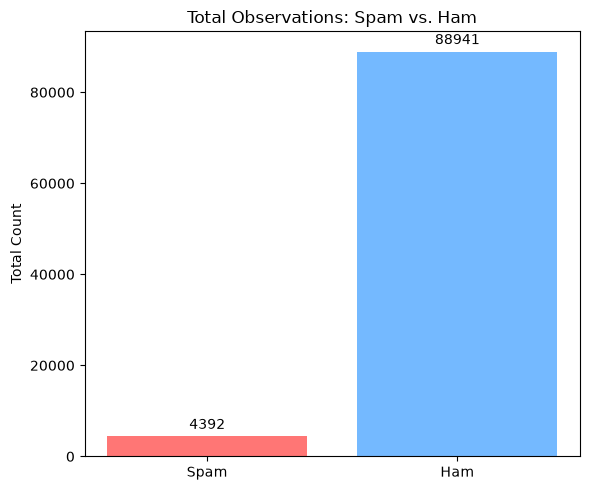

In [17]:
counts = [len(spam), len(ham)]
labels = ['Spam', 'Ham']

fig, ax = plt.subplots(figsize=(6, 5))
bars = ax.bar(labels, counts, color=['#ff7675', '#74b9ff'])

# Add the count labels on top of the bars
ax.bar_label(bars, padding=3)

ax.set_ylabel('Total Count')
ax.set_title('Total Observations: Spam vs. Ham')
plt.tight_layout()
plt.show()

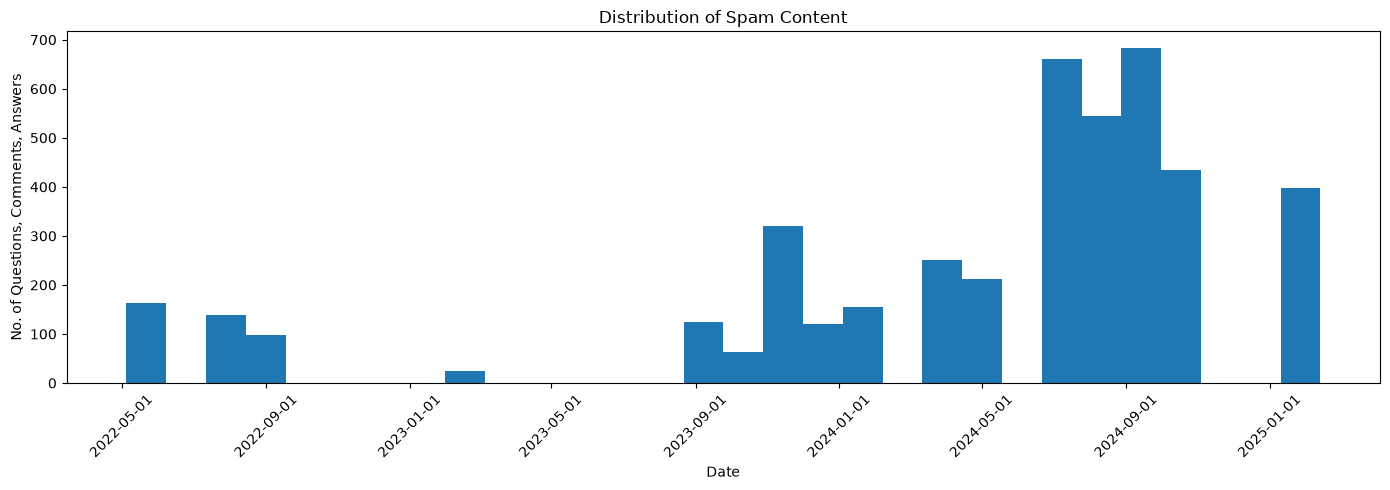

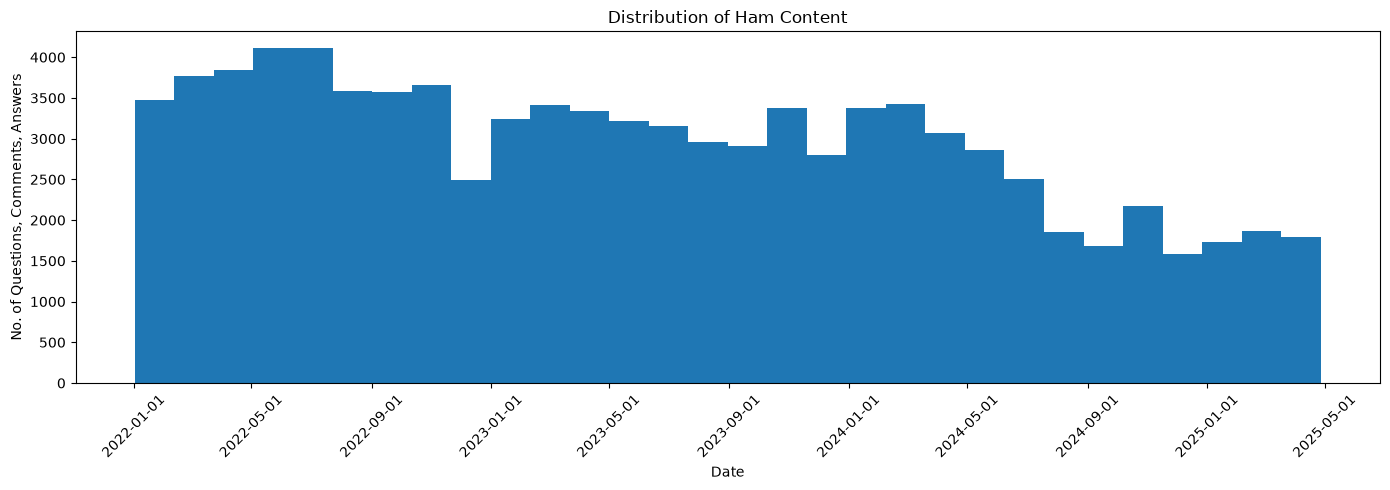

In [18]:
#Plot distribution of spam
spam['created_at'] = pd.to_datetime(spam['created_at'])

plt.figure(figsize=(14, 5))

plt.hist(spam['created_at'], bins=30)

plt.gca().xaxis.set_major_formatter(
    mdates.DateFormatter('%Y-%m-%d')
)

plt.xticks(rotation=45)
plt.xlabel('Date')
plt.ylabel('No. of Questions, Comments, Answers')
plt.title('Distribution of Spam Content')
plt.tight_layout()
plt.show()

#Plot distribution of ham
ham['created_at'] = pd.to_datetime(ham['created_at'])

plt.figure(figsize=(14, 5))

plt.hist(ham['created_at'], bins=30)

plt.gca().xaxis.set_major_formatter(
    mdates.DateFormatter('%Y-%m-%d')
)

plt.xticks(rotation=45)
plt.xlabel('Date')
plt.ylabel('No. of Questions, Comments, Answers')
plt.title('Distribution of Ham Content')
plt.tight_layout()
plt.show()

In [19]:
print("Check empty body in Spam")
print(spam[spam["body"].isna()])

print("Check empty body in Ham")
print(ham[ham["body"].isna()])

print(len(ham))
ham = ham.dropna(subset=["body"]).reset_index(drop=True)
print("Ham after removing NA",len(ham))

Check empty body in Spam
Empty DataFrame
Columns: [created_at, subdomain, table, body, label, label_description]
Index: []
Check empty body in Ham
               created_at subdomain        table body
20596 2022-06-20 08:05:09   support   hc_answers  NaN
30061 2025-04-18 17:31:36   support  hc_comments  NaN
49287 2023-02-21 19:22:35   support   hc_answers  NaN
81843 2023-02-09 00:52:17   support   hc_answers  NaN
88941
Ham after removing NA 88937


In [20]:
ham["is_spam"] = 0
spam["is_spam"] = 1

all_data = pd.concat([ham, spam], ignore_index=True)

display(all_data)

,created_at,subdomain,table,body,is_spam,label,label_description
0,2023-02-24 01:52:08,support,hc_answers,"<p>Hi Serge, thanks for the feedback! Agreed t...",0,NaN,NaN
1,2022-06-22 20:38:15,support,hc_comments,"<p><x-zendesk-user data-user-name=""Niall Colfe...",0,NaN,NaN
2,2022-11-04 14:14:18,support,hc_comments,<p>Has anybody managed to get this setup using...,0,NaN,NaN
3,2023-04-11 07:27:27,support,hc_answers,"<div class=""zd-comment"" dir=""auto"">Hi Rey,<br>...",0,NaN,NaN
4,2022-05-09 16:19:22,support,hc_answers,<p>I too am trying to accomplish this but have...,0,NaN,NaN
...,...,...,...,...,...,...,...
93324,2025-02-12 09:40:41,hvasrv,hc_questions,[8!8!8!984!5!8!4!0] Does TotalAV 24/7 Support?...,1,12.0,Any other type of spam
93325,2025-02-12 11:19:40,fezxdz,hc_questions,is coinbase support 24 7,1,12.0,Any other type of spam
93326,2025-02-12 05:13:43,vmmhk,hc_questions,Global Warming: The Emergent Threat to Our Ear...,1,10.0,Ads for any other type of merchandise
93327,2025-02-12 10:29:32,hmstzz,hc_questions,How to Contact SBCGlobal Email Support Quickly...,1,11.0,Fraud - impersonating legitimate organization ...


In [21]:
duplicates = all_data[
    all_data[["body"]].duplicated(keep=False)
].sort_values("body")

display(duplicates[["body", "is_spam"]])

,body,is_spam
92800,How do | contact || Blockchain Support Number...,1
92807,How do | contact || Blockchain Support Number...,1
90467,"""Seamless Refund Experience: Norton's Customer...",1
90449,"""Seamless Refund Experience: Norton's Customer...",1
2522,"""Ticket.conversation.property"" is not triggeri...",0
...,...,...
91748,¿Cómo hablo con el servicio de atención al cli...,1
89283,Ãlîght møtīôñ,1
89280,Ãlîght møtīôñ,1
90806,【Quick:Assistance™】What is the cancellation po...,1


In [22]:
#Check conflicting labels across ham and spam
label_conflicts = (
    all_data.groupby("body")["is_spam"]
      .nunique()
      .loc[lambda x: x > 1]
)

print("Number of conflicting bodies:", (label_conflicts))
print(list(label_conflicts))

Number of conflicting bodies: body
<p>Great info check more on https://mauricettecalculette.fr/</p>    2
<p>test</p>                                                         2
Name: is_spam, dtype: int64
[2, 2]


In [23]:
conflicts = all_data[
    all_data["body"].isin(label_conflicts.index)
]

print(conflicts[["body", "is_spam"]].to_string(index=False))

                                                            body  is_spam
                                                     <p>test</p>        0
                                                     <p>test</p>        0
                                                     <p>test</p>        0
                                                     <p>test</p>        0
                                                     <p>test</p>        0
                                                     <p>test</p>        0
                                                     <p>test</p>        0
                                                     <p>test</p>        0
<p>Great info check more on https://mauricettecalculette.fr/</p>        0
                                                     <p>test</p>        0
                                                     <p>test</p>        0
<p>Great info check more on https://mauricettecalculette.fr/</p>        1
                                      

In [24]:
# Set conflicting bodies to ham (0) as they don't represent abuse
all_data.loc[
    all_data["body"].isin(label_conflicts.index),
    "is_spam"
] = 0

In [25]:
#Check if labels are correct
print(
    all_data[all_data["body"].isin(label_conflicts.index)]
    [["body", "is_spam"]]
    .to_string(index=False)
)

                                                            body  is_spam
                                                     <p>test</p>        0
                                                     <p>test</p>        0
                                                     <p>test</p>        0
                                                     <p>test</p>        0
                                                     <p>test</p>        0
                                                     <p>test</p>        0
                                                     <p>test</p>        0
                                                     <p>test</p>        0
<p>Great info check more on https://mauricettecalculette.fr/</p>        0
                                                     <p>test</p>        0
                                                     <p>test</p>        0
<p>Great info check more on https://mauricettecalculette.fr/</p>        0
                                      

In [26]:
print("Rows before:", len(all_data))
print("Duplicate bodies:", all_data.duplicated(subset=["created_at","body"]).sum())

all_data = (
    all_data
    .drop_duplicates(subset=["created_at","body"], keep="first")
    .reset_index(drop=True)
)

print("Rows after:", len(all_data))

Rows before: 93329
Duplicate bodies: 6
Rows after: 93323


In [27]:
print("Total rows:", len(all_data))
print("\nClass distribution:")
print(all_data["is_spam"].value_counts())

print("\nClass proportions:")
print(all_data["is_spam"].value_counts(normalize=True).round(3))

print("\nMissing bodies:", all_data["body"].isna().sum())
print("Duplicate bodies:", all_data["body"].duplicated().sum())

Total rows: 93323

Class distribution:
is_spam
0    88935
1     4388
Name: count, dtype: int64

Class proportions:
is_spam
0    0.953
1    0.047
Name: proportion, dtype: float64

Missing bodies: 0
Duplicate bodies: 1837


In [28]:
display(all_data[['created_at','subdomain', 'table', 'body', 'is_spam']])

,created_at,subdomain,table,body,is_spam
0,2023-02-24 01:52:08,support,hc_answers,"<p>Hi Serge, thanks for the feedback! Agreed t...",0
1,2022-06-22 20:38:15,support,hc_comments,"<p><x-zendesk-user data-user-name=""Niall Colfe...",0
2,2022-11-04 14:14:18,support,hc_comments,<p>Has anybody managed to get this setup using...,0
3,2023-04-11 07:27:27,support,hc_answers,"<div class=""zd-comment"" dir=""auto"">Hi Rey,<br>...",0
4,2022-05-09 16:19:22,support,hc_answers,<p>I too am trying to accomplish this but have...,0
...,...,...,...,...,...
93318,2025-02-12 09:40:41,hvasrv,hc_questions,[8!8!8!984!5!8!4!0] Does TotalAV 24/7 Support?...,1
93319,2025-02-12 11:19:40,fezxdz,hc_questions,is coinbase support 24 7,1
93320,2025-02-12 05:13:43,vmmhk,hc_questions,Global Warming: The Emergent Threat to Our Ear...,1
93321,2025-02-12 10:29:32,hmstzz,hc_questions,How to Contact SBCGlobal Email Support Quickly...,1


### Extract Features (URL Count)

In [29]:
import re

url_pattern = re.compile(
    r'https?://[^\s"\'<>]+|www\.[^\s"\'<>]+',
    flags=re.IGNORECASE
)

all_data["url_count"] = (
    all_data["body"]
    .astype(str)
    .apply(lambda text: len(url_pattern.findall(text)))
)

pd.set_option("display.expand_frame_repr", False)
pd.set_option("display.width", 1000)
pd.set_option("display.max_columns", None)

summary = (
    all_data.groupby("is_spam")["url_count"]
    .agg(["count", "sum", "mean", "median", "std", "min", "max"])
    .rename(index={0: "Ham", 1: "Spam"})
    .reset_index()
)

display(summary)


,is_spam,count,sum,mean,median,std,min,max
0,Ham,88935,27245,0.306347,0.0,0.942595,0,71
1,Spam,4388,7187,1.637876,0.0,5.820614,0,113


In [30]:
all_data["has_url"] = all_data["url_count"] > 0

display(
    (
        all_data.groupby("is_spam")["has_url"]
        .mean()
        .mul(100)
        .rename(index={0: "Ham", 1: "Spam"})
        .round(2)
        .rename("url_percentage")
        .reset_index()
    )
)

,is_spam,url_percentage
0,Ham,18.26
1,Spam,43.80


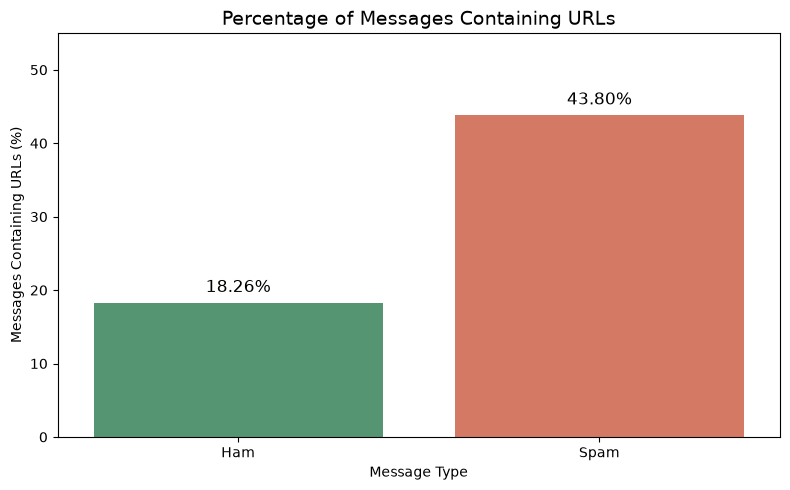

In [31]:
url_percentage = (
    all_data.groupby("is_spam")["url_count"]
    .apply(lambda x: (x > 0).mean() * 100)
    .reset_index(name="url_percentage")
)

url_percentage["is_spam"] = url_percentage["is_spam"].map({
    0: "Ham",
    1: "Spam"
})

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=url_percentage,
    x="is_spam",
    y="url_percentage",
    hue="is_spam",
    palette={"Ham": "#4C9F70", "Spam": "#E76F51"},
    legend=False
)

# Add percentage labels
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f%%",
        padding=5,
        fontsize=12
    )

plt.title("Percentage of Messages Containing URLs", fontsize=14)
plt.xlabel("Message Type")
plt.ylabel("Messages Containing URLs (%)")
plt.ylim(0, 55)
plt.tight_layout()
plt.show()

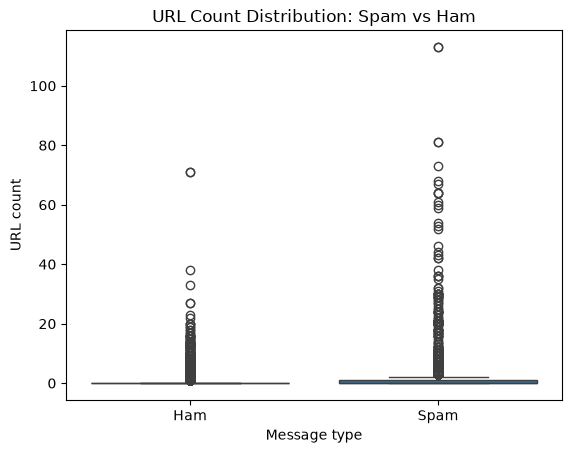

In [32]:
plot_data = all_data.copy()

sns.boxplot(
    data=plot_data,
    x="is_spam",
    y="url_count"
)

plt.xticks([0, 1], ["Ham", "Spam"])
plt.xlabel("Message type")
plt.ylabel("URL count")
plt.title("URL Count Distribution: Spam vs Ham")
plt.show()

In [33]:
# Separate URL counts
ham_urls = all_data.loc[
    all_data["is_spam"] == 0, "url_count"
].dropna()

spam_urls = all_data.loc[
    all_data["is_spam"] == 1, "url_count"
].dropna()

# Mann-Whitney U test
stat, p_value = mannwhitneyu(
    spam_urls,
    ham_urls,
    alternative="greater"
)

# Sample sizes
n_spam = len(spam_urls)
n_ham = len(ham_urls)

# Medians
spam_median = spam_urls.median()
ham_median = ham_urls.median()

# Effect size: rank-biserial correlation
effect_size = (2 * stat / (n_spam * n_ham)) - 1

print("Spam sample size:", n_spam)
print("Ham sample size:", n_ham)

print("Spam median URL count:", spam_median)
print("Ham median URL count:", ham_median)

print("Mann-Whitney U statistic:", stat)
print(f"P-value: {p_value:.10e}")
print("Rank-biserial effect size:", effect_size)

if p_value < 0.05:
    print("Result: Spam messages tend to have significantly more URLs.")
else:
    print("Result: No statistically significant evidence that spam messages tend to have more URLs.")


Spam sample size: 4388
Ham sample size: 88935
Spam median URL count: 0.0
Ham median URL count: 0.0
Mann-Whitney U statistic: 246769604.5
P-value: 0.0000000000e+00
Rank-biserial effect size: 0.26468489759223646
Result: Spam messages tend to have significantly more URLs.


In [34]:
def fix_encoding(text):
    if pd.isna(text):
        return text

    try:
        return text.encode("latin1").decode("utf-8")
    except (UnicodeEncodeError, UnicodeDecodeError):
        return text

all_data["body_utf"] = all_data["body"].apply(fix_encoding)
display(all_data.head())

,created_at,subdomain,table,body,is_spam,label,label_description,url_count,has_url,body_utf
0,2023-02-24 01:52:08,support,hc_answers,"<p>Hi Serge, thanks for the feedback! Agreed t...",0,NaN,NaN,0,False,"<p>Hi Serge, thanks for the feedback! Agreed t..."
1,2022-06-22 20:38:15,support,hc_comments,"<p><x-zendesk-user data-user-name=""Niall Colfe...",0,NaN,NaN,0,False,"<p><x-zendesk-user data-user-name=""Niall Colfe..."
2,2022-11-04 14:14:18,support,hc_comments,<p>Has anybody managed to get this setup using...,0,NaN,NaN,0,False,<p>Has anybody managed to get this setup using...
3,2023-04-11 07:27:27,support,hc_answers,"<div class=""zd-comment"" dir=""auto"">Hi Rey,<br>...",0,NaN,NaN,0,False,"<div class=""zd-comment"" dir=""auto"">Hi Rey,<br>..."
4,2022-05-09 16:19:22,support,hc_answers,<p>I too am trying to accomplish this but have...,0,NaN,NaN,0,False,<p>I too am trying to accomplish this but have...


### Clean HTML Tags

In [35]:
def clean_html(text):

    if pd.isna(text):
        return text

    text = str(text)

    # Decode HTML entities
    text = html.unescape(text)

    # Check whether actual HTML tags exist
    if not re.search(r'<[a-zA-Z][^>]*>', text):
        return text.strip()

    # Suppress only BeautifulSoup's URL-like markup warning
    with warnings.catch_warnings():
        warnings.simplefilter(
            "ignore",
            MarkupResemblesLocatorWarning
        )

        soup = BeautifulSoup(text, "html.parser")

    # Remove HTML comments
    for comment in soup.find_all(
        string=lambda t: isinstance(t, Comment)
    ):
        comment.extract()

    # Preserve hyperlinks and URLs
    for link in soup.find_all("a"):
        url = link.get("href", "")
        link_text = link.get_text(" ", strip=True)

        replacement = f"{link_text} {url}" if url else link_text
        link.replace_with(replacement)

    # Preserve line breaks
    for tag in soup.find_all("br"):
        tag.replace_with("\n")

    # Preserve structural boundaries
    for tag in soup.find_all(["p", "div", "tr", "table", "li"]):
        tag.insert_before("\n")
        tag.insert_after("\n")

    # Extract readable text
    text = soup.get_text(" ", strip=False)

    # Remove remaining HTML-like tags
    text = re.sub(r"<[^>]+>", " ", text)

    # Normalize whitespace
    text = re.sub(r"[ \t]+", " ", text)
    text = re.sub(r" *\n *", "\n", text)
    text = re.sub(r"\n{3,}", "\n\n", text)

    return text.strip()

In [36]:
all_data["body_clean"] = all_data["body_utf"].apply(clean_html)

In [37]:
pd.set_option('display.max_rows', 5)

# Show all columns
pd.set_option('display.max_columns', None)

# Optional: Prevent column text from truncating if cells contain long strings
pd.set_option('display.max_colwidth', None)

# Optional: Prevent wrapping to a new line when the table is wide
pd.set_option('display.width', None)

display(all_data[['body','body_clean']].sample(20, random_state=66))

,body,body_clean
50984,"<p>Hi <x-zendesk-user data-user-name=""undefined"">4685946062746</x-zendesk-user> ,</p><p>This is an interesting use case. &nbsp;I can think of a few possible solutions, but I'm curious to know more about how exactly you use the organizations. &nbsp; Do you use it in reporting, in business rules, or do you have the account managers accessing the ZD Help Centre and viewing all tickets for their organization? &nbsp;Perhaps something else entirely? &nbsp;Because of the different features associated with organizations in Zendesk, there may be many different solutions or workarounds.</p><p>Cheers ~</p>","Hi 4685946062746 ,\n\nThis is an interesting use case. I can think of a few possible solutions, but I'm curious to know more about how exactly you use the organizations. Do you use it in reporting, in business rules, or do you have the account managers accessing the ZD Help Centre and viewing all tickets for their organization? Perhaps something else entirely? Because of the different features associated with organizations in Zendesk, there may be many different solutions or workarounds.\n\nCheers ~"
71816,<p>I have checked with the support team! Thank you.</p>\n<p>(It was due to the customized design setting and it needs to be checked with the internal web designer as it is out of Zendesk support's scope!)</p>,I have checked with the support team! Thank you.\n\n(It was due to the customized design setting and it needs to be checked with the internal web designer as it is out of Zendesk support's scope!)
...,...,...
82621,"<div class=""zd-comment"" dir=""auto"">Hi everyone,<br> <br>Thank you for sharing your feedback with us. We appreciate your patience as we work on addressing your requests for more information. Rest assured, we are committed to providing a response as soon as we can. In the meantime, you may want to check our announcement page for updates.<br> <br>Thank you for your continued support!<br></div>","Hi everyone,\n \nThank you for sharing your feedback with us. We appreciate your patience as we work on addressing your requests for more information. Rest assured, we are committed to providing a response as soon as we can. In the meantime, you may want to check our announcement page for updates.\n \nThank you for your continued support!"
26964,"<div class=""zd-comment"" dir=""auto"">Hi Maor,<br> <br>I'll create a ticket for you. Please wait for my update via email and let's continue our conversation there.<br> <br>Cheers,<br>Dane<br>\n</div>","Hi Maor,\n \nI'll create a ticket for you. Please wait for my update via email and let's continue our conversation there.\n \nCheers,\nDane"


In [38]:
import re

html_pattern = r'<[^>]+>'

remaining_html = all_data[
    all_data["body_clean"].str.contains(
        html_pattern, na=False, regex=True
    )
]

print("Rows with potential remaining HTML:", len(remaining_html))

display(remaining_html[["body_clean"]].head(20))

Rows with potential remaining HTML: 1


,body_clean
89856,"A B C D E F G H I J K L M N O P Q R S T U V W X Y Z À Å É Î Õ Ø a b c d e f g h i j k l m n o p q r s t u v w x y z à å é î õ ø & 1 2 3 4 5 6 7 8 9 0 ( $ ¥ € £ . , ! ? * ~ # @ % : ; ' "" ^ < > _ / \ | )..."


In [39]:
display(all_data.loc[[89856]])

,created_at,subdomain,table,body,is_spam,label,label_description,url_count,has_url,body_utf,body_clean
89856,2023-11-26 15:49:24,pkkwslqs,hc_questions,"A B C D E F G H I J K L M N O P Q R S T U V W X Y Z À Å É Î Õ Ø a b c d e f g h i j k l m n o p q r s t u v w x y z à å é î õ ø & 1 2 3 4 5 6 7 8 9 0 ( $ ¥ € £ . , ! ? * ~ # @ % : ; ' "" ^ < > _ / \ | )...\n",1,12.0,Any other type of spam,0,False,"A B C D E F G H I J K L M N O P Q R S T U V W X Y Z À Å É Î Õ Ø a b c d e f g h i j k l m n o p q r s t u v w x y z à å é î õ ø & 1 2 3 4 5 6 7 8 9 0 ( $ ¥ € £ . , ! ? * ~ # @ % : ; ' "" ^ < > _ / \ | )...\n","A B C D E F G H I J K L M N O P Q R S T U V W X Y Z À Å É Î Õ Ø a b c d e f g h i j k l m n o p q r s t u v w x y z à å é î õ ø & 1 2 3 4 5 6 7 8 9 0 ( $ ¥ € £ . , ! ? * ~ # @ % : ; ' "" ^ < > _ / \ | )..."


In [40]:
# Remove missing and empty messages
all_data["body_clean"] = (
    all_data["body_clean"]
    .fillna("")
    .astype(str)
    .str.strip()
)

# Extract unique messages
unique_bodies = all_data.loc[
    all_data["body_clean"] != "",
    "body_clean"
].unique().tolist()

print("Total messages:", len(all_data))
print("Unique messages:", len(unique_bodies))
print("Diff:", len(all_data) - len(unique_bodies))

Total messages: 93323
Unique messages: 91199
Diff: 2124


### Detect non-English text

In [41]:
from lingua import LanguageDetectorBuilder

detector = (
    LanguageDetectorBuilder
    .from_all_languages()
    .build()
)

def detect_language(text):

    if not isinstance(text, str) or len(text.strip()) < 10:
        return None

    language = detector.detect_language_of(text)

    if language is None:
        return None

    return language.iso_code_639_1.name.lower()

In [42]:
from tqdm import tqdm
detected_languages = {}

for text in tqdm(unique_bodies, desc="Detecting languages"):

    try:
        detected_languages[text] = detect_language(text)

    except Exception:
        detected_languages[text] = None

# Add language column
all_data["language"] = all_data["body_clean"].map(
    detected_languages
)

Detecting languages: 100%|██████████| 91199/91199 [06:25<00:00, 236.50it/s]


### Language Translation (Top 15 Languages)

In [57]:
top_15_languages = (
    all_data.loc[
        all_data["language"] != "en",
        "language"
    ]
    .value_counts()
    .head(15)
)

print(top_15_languages)
print("\nTotal messages:", top_15_languages.sum())

language
pt    1068
es     980
      ... 
cy      31
mi      28
Name: count, Length: 15, dtype: int64

Total messages: 4285


In [56]:
nan_samples = all_data[all_data['language'].isna()]['is_spam'].value_counts()
print(nan_samples)
#for text in nan_samples:
#    print(f'- Text: {repr(text)}')

# Filter for rows where language is NaN AND is_spam is 1 (spam)
spam_nan_rows = all_data[all_data['language'].isna() & (all_data['is_spam'] == 1)]

print(f'Total spam rows with missing language: {len(spam_nan_rows)}')

# Print the text body_clean for all or a sample of them
for text in spam_nan_rows['body_clean']:
  print(f'- Text: {repr(text)}')

is_spam
0    706
1     85
Name: count, dtype: int64
Total spam rows with missing language: 85
- Text: '">'
- Text: '">\n">'
- Text: ''
- Text: ''
- Text: ''
- Text: ''
- Text: ''
- Text: 'click'
- Text: 'src="">'
- Text: '—'
- Text: ''
- Text: '—'
- Text: 'test\ntest'
- Text: 'GghGgg'
- Text: 'test test'
- Text: 'Textfree'
- Text: '984031642'
- Text: 'Wastap'
- Text: '081 6852'
- Text: '가입코드\n가입코드'
- Text: 'com\ncom'
- Text: 'Ads'
- Text: 'test'
- Text: '𝟙-𝟠ӠӠ-Ӡ𝟙7-⊘ƼϬϬ How do I recover my Cash App account? {Quick Support Instant}\n𝟙-𝟠ӠӠ-Ӡ𝟙7-⊘ƼϬϬ𝟙-𝟠ӠӠ-Ӡ𝟙7-⊘ƼϬϬ𝟙-𝟠ӠӠ-Ӡ𝟙7-⊘ƼϬϬ𝟙-𝟠ӠӠ-Ӡ𝟙7-⊘ƼϬϬ𝟙-𝟠ӠӠ-Ӡ𝟙7-⊘ƼϬϬ𝟙-𝟠ӠӠ-Ӡ𝟙7-⊘ƼϬϬ𝟙-𝟠ӠӠ-Ӡ𝟙7-⊘ƼϬϬ𝟙-𝟠ӠӠ-Ӡ𝟙7-⊘ƼϬϬ𝟙-𝟠ӠӠ-Ӡ𝟙7-⊘ƼϬϬ𝟙-𝟠ӠӠ-Ӡ𝟙7-⊘ƼϬϬ𝟙-𝟠ӠӠ-Ӡ𝟙7-⊘ƼϬϬ𝟙-𝟠ӠӠ-Ӡ𝟙7-⊘ƼϬϬ𝟙-𝟠ӠӠ-Ӡ𝟙7-⊘ƼϬϬ𝟙-𝟠ӠӠ-Ӡ𝟙7-⊘ƼϬϬ𝟙-𝟠ӠӠ-Ӡ𝟙7-⊘ƼϬϬ𝟙-𝟠ӠӠ-Ӡ𝟙7-⊘ƼϬϬ𝟙-𝟠ӠӠ-Ӡ𝟙7-⊘ƼϬϬ𝟙-𝟠ӠӠ-Ӡ𝟙7-⊘ƼϬϬ𝟙-𝟠ӠӠ-Ӡ𝟙7-⊘ƼϬϬ𝟙-𝟠ӠӠ-Ӡ𝟙7-⊘ƼϬϬ𝟙-𝟠ӠӠ-Ӡ𝟙7-⊘ƼϬϬ𝟙-𝟠ӠӠ-Ӡ𝟙7-⊘ƼϬϬ𝟙-𝟠ӠӠ-Ӡ𝟙7-⊘ƼϬϬ𝟙-𝟠ӠӠ-Ӡ𝟙7-⊘ƼϬϬ𝟙-𝟠ӠӠ-Ӡ𝟙7-⊘ƼϬϬ𝟙-𝟠ӠӠ-Ӡ𝟙7-⊘ƼϬϬ𝟙-𝟠ӠӠ-Ӡ𝟙7-⊘ƼϬϬ𝟙-𝟠ӠӠ-Ӡ𝟙7-⊘ƼϬϬ𝟙-𝟠ӠӠ-Ӡ𝟙7-⊘ƼϬϬ𝟙-𝟠ӠӠ-Ӡ𝟙7-⊘ƼϬϬ𝟙-𝟠ӠӠ-Ӡ𝟙7-⊘ƼϬϬ𝟙-𝟠ӠӠ-Ӡ𝟙7-⊘ƼϬϬ𝟙-𝟠ӠӠ-Ӡ𝟙7-⊘ƼϬϬ𝟙

In [44]:
all_data['is_english'] = all_data['language'] == 'en'

english_comparison = (
    all_data.groupby('is_english')['is_spam']
    .agg(
        total_count='count',
        spam_count='sum',
        spam_percentage=lambda x: (x.sum() / len(x)) * 100,
    )
    .reset_index()
)

# Rename the boolean flag for readability
english_comparison['is_english'] = english_comparison['is_english'].map(
    {True: 'English (en)', False: 'Non-English'}
)

print('\n--- English vs. Non-English Spam % ---')
print(english_comparison)


--- English vs. Non-English Spam % ---
     is_english  total_count  spam_count  spam_percentage
0   Non-English         5397         965        17.880304
1  English (en)        87926        3423         3.893046


In [58]:
from transformers import MarianMTModel, MarianTokenizer
from huggingface_hub import model_info
import torch

device = "cuda" if torch.cuda.is_available() else "cpu"

top_models = {
    "pt": "Helsinki-NLP/opus-mt-ROMANCE-en",
    "es": "Helsinki-NLP/opus-mt-es-en",
    "ko": "Helsinki-NLP/opus-mt-ko-en",
    "ja": "Helsinki-NLP/opus-mt-ja-en",
    "de": "Helsinki-NLP/opus-mt-de-en",
    "fr": "Helsinki-NLP/opus-mt-fr-en",
    "la": None,
    "da": "Helsinki-NLP/opus-mt-da-en",
    "id": "Helsinki-NLP/opus-mt-id-en",
    "tl": "Helsinki-NLP/opus-mt-tl-en",
    "ar": "Helsinki-NLP/opus-mt-ar-en",
    "it": "Helsinki-NLP/opus-mt-it-en",
    "nl": "Helsinki-NLP/opus-mt-nl-en",
    "eo": "Helsinki-NLP/opus-mt-eo-en",
    "zh": "Helsinki-NLP/opus-mt-zh-en"
}

translation_models = {}

for lang, model_name in top_models.items():

    print(f"Loading {lang}...")

    try:
        tokenizer = MarianTokenizer.from_pretrained(model_name)
        model = MarianMTModel.from_pretrained(model_name)

        model.to(device)
        model.eval()

        translation_models[lang] = {
            "tokenizer": tokenizer,
            "model": model
        }

        print(f"Loaded: {lang}")

    except Exception as e:
        print(f"Failed: {lang} - {e}")

print("\nLoaded languages:", list(translation_models.keys()))

Loading pt...


Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

Loaded: pt
Loading es...


Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

Loaded: es
Loading ko...


Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

... (19 outputs left out)

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

Loaded: eo
Loading zh...


Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

Loaded: zh

Loaded languages: ['pt', 'es', 'ko', 'ja', 'de', 'fr', 'da', 'id', 'tl', 'ar', 'it', 'nl', 'eo', 'zh']


In [59]:
pd.set_option('display.max_rows', None)
coverage = pd.DataFrame({
    "messages": top_15_languages,
    "model_available": [
        bool(top_models.get(lang))
        for lang in top_15_languages.index
    ]
})

display(coverage)

,messages,model_available
language,,
pt,1068,True
es,980,True
ko,534,True
ja,431,True
de,419,True
fr,405,True
la,78,False
da,71,True
id,70,True


In [60]:

import gc
import torch
import pickle
from tqdm.auto import tqdm
from transformers import MarianMTModel, MarianTokenizer

device = "cuda" if torch.cuda.is_available() else "cpu"

BACKUP_FILE = "opus_translations_repaired.pkl"
SAVE_INTERVAL = 25

# --------------------------------------------------
# Load previous translations and resume
# --------------------------------------------------

# Initialize translation dictionary
if "opus_translations" not in globals():
    opus_translations = {}

try:
    with open(BACKUP_FILE, "rb") as f:
        saved_translations = pickle.load(f)

    # Restore successful translations only
    for text, translation in saved_translations.items():
        if translation is not None and translation.strip():
            opus_translations[text] = translation

    print("Restored translations:", len(opus_translations))

except FileNotFoundError:
    print("No previous backup found. Starting fresh.")

# --------------------------------------------------
# 1. Identify messages requiring translation
# --------------------------------------------------

translate_data = (
    all_data[
        all_data["language"].isin(top_models.keys())
        & (all_data["language"] != "en")
    ][["language", "body_clean"]]
    .dropna()
    .drop_duplicates(subset=["body_clean"])
)

remaining = [
    (row["body_clean"], row["language"])
    for _, row in translate_data.iterrows()
    if opus_translations.get(row["body_clean"]) is None
]

print("Messages requiring repair:", len(remaining))


# --------------------------------------------------
# 2. Long-text translation function
# --------------------------------------------------

def translate_long_text(text, tokenizer, model):

    encoded = tokenizer(
        text,
        add_special_tokens=False
    )["input_ids"]

    chunk_size = 400
    translated_chunks = []

    for start in range(0, len(encoded), chunk_size):

        chunk_ids = encoded[start:start + chunk_size]

        chunk_text = tokenizer.decode(
            chunk_ids,
            skip_special_tokens=True
        )

        inputs = tokenizer(
            chunk_text,
            return_tensors="pt",
            truncation=True,
            max_length=512
        )

        inputs = {
            key: value.to(device)
            for key, value in inputs.items()
        }

        with torch.no_grad():
            outputs = model.generate(
                **inputs,
                max_new_tokens=512,
                num_beams=4
            )

        translated = tokenizer.decode(
            outputs[0],
            skip_special_tokens=True
        )

        translated_chunks.append(translated)

    return " ".join(translated_chunks)


# --------------------------------------------------
# 3. Backup function
# --------------------------------------------------

def save_translations():

    with open(BACKUP_FILE, "wb") as f:
        pickle.dump(opus_translations, f)


# --------------------------------------------------
# 4. Process available languages
# --------------------------------------------------

successful = 0
failed = 0
skipped = 0
processed_count = 0

languages_to_process = sorted(
    set(lang for _, lang in remaining)
)

overall_progress = tqdm(
    total=len(remaining),
    desc="Overall translation",
    unit="message"
)

for lang in languages_to_process:

    model_name = top_models.get(lang)

    language_messages = [
        (text, language)
        for text, language in remaining
        if language == lang
    ]

    if not model_name:

        print(f"Skipping {lang}: No model available")

        skipped += len(language_messages)
        overall_progress.update(len(language_messages))
        continue

    print(f"\nLoading {lang}: {model_name}")

    try:
        tokenizer = MarianTokenizer.from_pretrained(model_name)

        model = MarianMTModel.from_pretrained(model_name)

        model.to(device)
        model.eval()

    except Exception as e:

        print(f"Could not load {lang}: {e}")

        skipped += len(language_messages)
        overall_progress.update(len(language_messages))
        continue

    for text, language in language_messages:

        try:
            result = translate_long_text(
                text,
                tokenizer,
                model
            )

            if result and result.strip():

                opus_translations[text] = result
                successful += 1

            else:
                failed += 1

        except Exception as e:

            failed += 1
            print(f"\nTranslation error ({lang}): {e}")

        processed_count += 1
        overall_progress.update(1)

        # Save every 25 processed messages
        if processed_count % SAVE_INTERVAL == 0:

            save_translations()

    # Save after each language
    save_translations()

    del model, tokenizer
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

overall_progress.close()


# --------------------------------------------------
# 5. Final backup
# --------------------------------------------------

save_translations()


# --------------------------------------------------
# 6. Final statistics
# --------------------------------------------------

total = successful + failed + skipped

print("\nTranslation recovery completed!")
print("Successfully repaired:", successful)
print("Failed:", failed)
print("Skipped:", skipped)
print("Total processed:", total)

if total:
    print(f"Success rate: {successful / total * 100:.2f}%")

print("Backup saved:", BACKUP_FILE)


Restored translations: 4099
Messages requiring repair: 77


Overall translation:   0%|          | 0/77 [00:00<?, ?message/s]

Skipping la: No model available

Translation recovery completed!
Successfully repaired: 0
Failed: 0
Skipped: 77
Total processed: 77
Success rate: 0.00%
Backup saved: opus_translations_repaired.pkl


In [53]:
samples = []

for text, translation in opus_translations.items():

    if translation is not None:
        samples.append({
            "Original": text,
            "Translation": translation
        })

sample_df = pd.DataFrame(samples)

display(
    sample_df.sample(
        min(5, len(sample_df)),
        random_state=40
    )
)

,Original,Translation
1918,"¿Cómo contactar a Aeromexico desde México?\n¿Has buscado recientemente “¿Cómo llamar a atención a clientes Aeromexico teléfono https://www.flyfaresky.com/es/articulos/como-llamar-a-aeromexico-en-mexico/ ?” en tu navegador web? ¿Necesita asistencia inmediata? ¡En ese caso! Coge tu móvil y marca Número de teléfono de Aeroméxico al +52 (55) 5133 4000 o 1-860-370-4608. Además, si llamas desde fuera de México, puedes marcar al 1-860-370-4608.","How to contact Aeromexico from Mexico? Have you recently searched “How to call Aeromexico customers’ attention by phone https://www.flyfaresky.com/en/articles/como-llamar-a-aeromexico-en-mexico/?” in your web browser? Do you need immediate assistance? In that case! Grab your mobile phone and make Aeromexico’s phone number at +52 (55) 5133 4000 or 1-860-370-4608. Also, if you call from outside Mexico, you can dial 1-860-370-4608."
4036,"Amazing timing, Sebastiaan!","Amazing timing, Sebastian!"
1693,"Gracias Jose por tu respuesta.\nMe surge otra consulta. Para los comentarios de los post pagos en facebook, una vez integrado, esos comentarios ingresan con las publicaciomes que se hicieron antes de la integración o aplica para aqurllos anuncios nuevos que se crean luego de integrarse.\nGracias","Thank you Jose for your reply. I get another query. For comments of post payments on facebook, once integrated, those comments enter with the posts that were made before integration or apply for new ads that are created after integration. Thank you"
1108,"Hola muy buenas Carlos!\n \nSi ustedes ya poseen el servicio de RingCentral, quizá lo mas sencillo sea utilizar la integración con esta empresa, puedes ver la App en nuestro Marketplace:\nRingCentral https://www.zendesk.com/marketplace/apps/support/43511/ringcentral/\n \nLa aplicación es desarralloada por RingCentral, por lo que cualquier gestión de soporte deberás comunicarte con ellos.\nEn caso que tengas mas consultas, te recomiendo generar un ticket con soporte así podemos asesorarte mas personalizadamente, o bien si lo solicitas puedo generar el ticket por ti.\n \nSaludos y buen fin de semana!","Hello very good Carlos! If you already have the service of RingCentral, perhaps the easiest thing is to use the integration with this company, you can see the App in our Marketplace: RingCentral https://www.zendesk.com/marketplace/apps/support/43511/ringcentral/ The application is uprooted by RingCentral, so any support management you must communicate with them. In case you have more queries, I recommend you generate a ticket with support so we can advise you more personalizedly, or if you request I can generate the ticket for you. Greetings and good weekend!"
52,"Olá Kelly! \n\nVocê está tendo problemas para receber seu código 2FA? Se sim, você pode pedir a um de seus administradores para gerar códigos de recuperação para você. Para referência: Obtendo um código de recuperação para outra pessoa https://support.zendesk.com/hc/en-us/articles/4408826974874-Managing-two-factor-authentication-for-agents-and-admins#topic_prq_v5v_tv\n\nEu espero que isso ajude!","Hello Kelly! Are you having trouble getting your 2FA code? If so, you can ask one of your administrators to generate recovery codes for you. For reference: Getting a recovery code for someone else https://support.zendesk.com/hc/en-us/articles/440826974874-Managing-two-factor-authentication-for-agents-and-admins#topic_prq_v5v_tv I hope this helps!"


In [46]:
# --------------------------------------------------
# Add translations back to all_data
# --------------------------------------------------

# Start with original cleaned text (English messages remain unchanged)
all_data["body_english"] = all_data["body_clean"]

# Identify non-English messages
translate_mask = (
    all_data["language"].isin(top_models.keys())
    & (all_data["language"] != "en")
)

# Replace with repaired English translations
all_data.loc[translate_mask, "body_english"] = (
    all_data.loc[translate_mask, "body_clean"]
    .map(opus_translations)
    .fillna(all_data.loc[translate_mask, "body_clean"])
)

In [47]:
# --------------------------------------------------
# Check results
# --------------------------------------------------

print("Total messages:", len(all_data))
print("Translated messages:", 
      (translate_mask & all_data["body_english"].ne(all_data["body_clean"])).sum())

print("Missing translations:",
      (translate_mask & all_data["body_clean"].map(opus_translations).isna()).sum())

print("\nSample:")
display(
    all_data.loc[
        translate_mask,
        ["language", "body_clean", "body_english"]
    ].head(10)
)

Total messages: 93323
Translated messages: 4100
Missing translations: 78

Sample:


,language,body_clean,body_english
102,de,Gibt es auch eine Möglichkeit für das Dataset “Tickets”?,Is there also a possibility for the Dataset tickets?
141,de,"Hallo Neda, diesbezüglich gibt es kein aktuelles Problem. Wir haben gerade einen Test durchgeführt und die Anhänge können wie erwartet gesendet werden. Ich werde mit Ihnen ein Ticket erstellen, damit Sie mir einige Beispiele zur Verfügung stellen können.","Hello Neda, there is no current problem about this. We have just conducted a test and the attachments can be sent as expected. I will create a ticket with you so that you can provide me with some examples."
157,es,"Hola Nacho! De acuerdo a tu respuesta, tenemos tickets que cumplen 100% con la métrica One-touch tickets que tienen más de una respuesta por parte de los agentes, por lo que no me parece que has resuelto mi consulta. Creo que deberías hacer una comparación entre un ticket que marca 100% y los que marcan 0% y de verdad ver cuál es la condición REAL que está generando la situación planteada.","Hello Nacho! According to your answer, we have tickets that meet 100% with the One-touch tickets metric that have more than one response from agents, so it doesn’t seem to me that you have solved my query. I think you should make a comparison between a ticket that marks 100% and those that mark 0% and really see what is the REAL condition that is generating the situation raised."
159,es,"Mensajería. ¿Servicio o seguridad? . Limitaciones de la sugerencia de artículos automatizada.\nTeniendo activada la mensajería la función de sugerencias de artículos automatizadas, que busca artículos pertinentes en el centro de ayuda en función de las entradas de texto libre de los clientes en el web widget no encuentra los artículos para sugerir si estos , o el Centro de ayuda, tienen restricciones de seguridad , como: \n1) Visibilidad por segmento (aunque el usuario sea parte del segmento ) \n 2) Si en Guide está activada la opción de requerir ""Requerir Inicio de Sesión en el Centro de ayuda"". \nConsidero que ambas opciones son muy útiles y sería bueno que sean compatibles con las sugerencias automatizadas.","Messaging. Service or security? . Limitations of automated article suggestion. Having enabled the messaging function of automated article suggestions, which searches for relevant articles in the help center depending on the free text entries of customers in the web widget you do not find the articles to suggest if these, or the Help Center, have security restrictions , such as: 1) Visibility by segment (even if the user is part of the segment ) 2) If the option to require ""Require Login in the Help Center"" is enabled, I think both options are very useful and it would be good if they were compatible with automated suggestions."
180,de,"Option 2 ist ja ok, was aber wenn andere Agenten mich als Follower hinzufügen?","Option 2 is okay, but what if other agents add me as a follower?"
221,de,"Hallo! Mein Deutsch ist schwach, aber ich denke ich kann hilfe. Sie können ein neuen Auslöser hinzufügen , und die Name des Agents durchsuchen auf dem ersten kommentar:","Hello! My German is weak, but I think I can help. You can add a new trigger, and search the name of the agent on the first comment:"
232,es,"hola buenos dias, queremos cancelar una cuenta de zopim chat y no nos deja, no podemos ni ingresar, hace mas de 1 año que no lo usamos y nos siguen cobrando. Preciso ayuda, es una estafa esto\n\n \n\ngracias","Hello good morning, we want to cancel a zopim chat account and do not leave us, we can neither enter, we have not used it for more than 1 year and continue to charge us. Precise help, it is a scam this thank you"
239,pt,"Notificação de abertura de tickets em massa\nOi pessoal, estou buscando uma forma de receber uma notificação para cenário onde um único usuário final abre mais de 3 ticket em curto período de tempo.\n\nEm contato com suporte me informaram que não existe função nativa Zendesk que realize tal ação mas que poderia exi

In [48]:
display(all_data.head())

,created_at,subdomain,table,body,is_spam,label,label_description,url_count,has_url,body_utf,body_clean,language,body_english
0,2023-02-24 01:52:08,support,hc_answers,"<p>Hi Serge, thanks for the feedback! Agreed that the side conversation notifications need to live in a place like the Home Dashboard like you suggested. Unfortunately, the existing dashboard activity stream is only designed to list specific types of Ticket events, but we do have other avenues we are currently exploring to make it easier to stay on top of the side conversation (and other) activities.</p>",0,NaN,NaN,0,False,"<p>Hi Serge, thanks for the feedback! Agreed that the side conversation notifications need to live in a place like the Home Dashboard like you suggested. Unfortunately, the existing dashboard activity stream is only designed to list specific types of Ticket events, but we do have other avenues we are currently exploring to make it easier to stay on top of the side conversation (and other) activities.</p>","Hi Serge, thanks for the feedback! Agreed that the side conversation notifications need to live in a place like the Home Dashboard like you suggested. Unfortunately, the existing dashboard activity stream is only designed to list specific types of Ticket events, but we do have other avenues we are currently exploring to make it easier to stay on top of the side conversation (and other) activities.",en,"Hi Serge, thanks for the feedback! Agreed that the side conversation notifications need to live in a place like the Home Dashboard like you suggested. Unfortunately, the existing dashboard activity stream is only designed to list specific types of Ticket events, but we do have other avenues we are currently exploring to make it easier to stay on top of the side conversation (and other) activities."
1,2022-06-22 20:38:15,support,hc_comments,"<p><x-zendesk-user data-user-name=""Niall Colfer"">1263082275569</x-zendesk-user> is there a way to remove the deleted organizations from showing up in explorer? I use a report to export data and we have 500+ deleted accounts from our initial seeding that I would like to remove.</p>",0,NaN,NaN,0,False,"<p><x-zendesk-user data-user-name=""Niall Colfer"">1263082275569</x-zendesk-user> is there a way to remove the deleted organizations from showing up in explorer? I use a report to export data and we have 500+ deleted accounts from our initial seeding that I would like to remove.</p>",1263082275569 is there a way to remove the deleted organizations from showing up in explorer? I use a report to export data and we have 500+ deleted accounts from our initial seeding that I would like to remove.,en,1263082275569 is there a way to remove the deleted organizations from showing up in explorer? I use a report to export data and we have 500+ deleted accounts from our initial seeding that I would like to remove.
2,2022-11-04 14:14:18,support,hc_comments,<p>Has anybody managed to get this setup using Azure AD to create agents with a custom role?<br />We have added mappings for role (set to 'agent') and custom_role_id (set to the id of the custom role to assign) but users are always created as end-user rather than as agent.<br /><br />Any ideas?<br />Thanks</p>,0,NaN,NaN,0,False,<p>Has anybody managed to get this setup using Azure AD to create agents with a custom role?<br />We have added mappings for role (set to 'agent') and custom_role_id (set to the id of the custom role to assign) but users are always created as end-user rather than as agent.<br /><br />Any ideas?<br />Thanks</p>,Has anybody managed to get this setup using Azure AD to create agents with a custom role?\nWe have added mappings for role (set to 'agent') and custom_role_id (set to the id of the custom role to assign) but users are always created as end-user rather than as agent.\n\nAny ideas?\nThanks,en,Has anybody managed to get this setup using Azure AD to create agents with a custom role?\nWe have added mappings for role (set to 'agent') and custom_r

In [ ]:
all_data.to_pickle("all_data_with_english_translations.pkl")

In [49]:
all_data.to_csv("all_data_with_english_translations.csv", index=False, encoding="utf-8-sig")

### Argos Translate (Not Using)

In [51]:
import argostranslate.package

argostranslate.package.update_package_index()

available = argostranslate.package.get_available_packages()

languages = ['sq', 'ar', 'az', 'eu', 'ca', 'zh', 'cs', 'da', 'nl', 'eo', 'et', 'fi', 'fr', 'de', 
             'el', 'he', 'hu', 'id', 'ga', 'it', 'ja', 'ko', 'lv', 'lt', 'ms', 'nb', 'pl', 'pt', 
             'ro', 'ru', 'sk', 'sl', 'es', 'sw', 'sv', 'tl', 'th', 'tr', 'vi']

for lang in languages:

    package = next(
        (
            p for p in available
            if p.from_code == lang
            and p.to_code == "en"
        ),
        None
    )

    if package:
        argostranslate.package.install_from_path(
            package.download()
        )
        print(f"Installed {lang} -> en")

    else:
        print(f"No direct package available: {lang}")

Installed sq -> en
Installed ar -> en
Installed az -> en
Installed eu -> en
Installed ca -> en
Installed zh -> en
Installed cs -> en
Installed da -> en
Installed nl -> en
Installed eo -> en
Installed et -> en
Installed fi -> en
Installed fr -> en
Installed de -> en
Installed el -> en
Installed he -> en
Installed hu -> en
Installed id -> en
Installed ga -> en
Installed it -> en
Installed ja -> en
Installed ko -> en
Installed lv -> en
Installed lt -> en
Installed ms -> en
Installed nb -> en
Installed pl -> en
Installed pt -> en
Installed ro -> en
Installed ru -> en
Installed sk -> en
Installed sl -> en
Installed es -> en
Installed sw -> en
Installed sv -> en
Installed tl -> en
Installed th -> en
Installed tr -> en
Installed vi -> en


In [ ]:
installed_languages = (
    argostranslate.translate.get_installed_languages()
)

english = next(
    (lang for lang in installed_languages if lang.code == "en"),
    None
)

if english is None:
    raise ValueError("English language package is not installed.")

translation_models = {}

for lang in installed_languages:

    if lang.code == "en":
        continue

    try:
        translation_models[lang.code] = lang.get_translation(
            english
        )

    except Exception:
        print(f"Translation unavailable: {lang.code}")

print("\nAvailable translation models:")
print(list(translation_models.keys()))

In [ ]:
supported_languages = list(translation_models.keys())

translate_mask = (
    all_data["language"].isin(supported_languages)
    & (all_data["language"] != "en")
)

unique_to_translate = (
    all_data.loc[translate_mask, "body_clean"]
    .dropna()
    .unique()
    .tolist()
)

print("Unique messages to translate:", len(unique_to_translate))
print("Supported languages:", supported_languages)

In [ ]:
def translate_to_english(text, lang):

    if not isinstance(text, str) or not text.strip():
        return text

    if lang == "en":
        return text

    model = translation_models.get(lang)

    if model is None:
        return None

    try:
        return model.translate(text)

    except Exception as e:
        print(f"Translation error ({lang}): {e}")
        return None

In [ ]:
from tqdm import tqdm
# Load previous translations
try:
    with open("translations_backup.pkl", "rb") as f:
        translations = pickle.load(f)

    print("Loaded previous translations:", len(translations))

except FileNotFoundError:
    translations = {}

display(len(translations))

In [ ]:
# Skip messages already processed
remaining = [
    text for text in unique_to_translate
    if text not in translations
]

print("Remaining messages:", len(remaining))

# Translation loop
for i, text in enumerate(tqdm(remaining, desc="Translating")):

    lang = detected_languages.get(text)

    try:
        translations[text] = translate_to_english(
            text, lang
        )

    except Exception as e:
        print(f"Failed ({lang}): {e}")
        translations[text] = None

    # Save every 50 messages
    if (i + 1) % 50 == 0:

        with open("translations_backup.pkl", "wb") as f:
            pickle.dump(translations, f)

# Final save
with open("translations_backup.pkl", "wb") as f:
    pickle.dump(translations, f)

print("Translation completed.")

In [ ]:
# Start with original cleaned text
all_data["body_english"] = all_data["body_clean"]

# Replace translated messages
all_data.loc[translate_mask, "body_english"] = (
    all_data.loc[translate_mask, "body_clean"].map(
        translations
    )
)

In [ ]:
print("Total records:", len(all_data))

print(
    "\nLanguage distribution:"
)

print(
    all_data["language"].value_counts(dropna=False)
)

print(
    "\nTranslation coverage:"
)

print("Non-null English text:",
      all_data["body_english"].notna().sum())

print("Missing English text:",
      all_data["body_english"].isna().sum())

print("Unique translations:",
      len(translations))

In [ ]:
translated_samples = all_data.loc[
    translate_mask,
    ["language", "body_clean", "body_english"]
].drop_duplicates()

translated_samples.sample(
    min(10, len(translated_samples)),
    random_state=56
)

In [ ]:
77309	es	Hola\n¿Como puedo cambiar o filtrar opciones de. lo que se muestra en la pestaña de Support/Panel para que no solo me muestre mis tickets abiertos y las estadisticas de mis tickets?\n\n¿Es posible poder modificar esa vista para poder seleccionar que mostrar en base a mi necesidad?	

mainstremainstremainstremainstremainstremainstremainstremainstremainstremainstremainstremainstremainstremainstremainstremainstremainstremainstremainstremainstremainstremainstremainstremainstremainstremainstremainstremainstremainstremainstremainstremainstremainstremainstremainstremainstremainstremainstremainstremainstremainstremainstremainstremainstremainstremainstremainstremainstremainstremainstremainstremainstremainstremainstre

In [ ]:
import re
import pandas as pd

def is_suspicious_translation(text):

    if not isinstance(text, str) or not text.strip():
        return True

    # Detect excessively repeated words or fragments
    if re.search(r'(.{3,20})\1{4,}', text):
        return True

    # Detect repeated mainst fragments
    if text.lower().count("mainstremainst") > 2:
        return True

    # Detect suspicious special tokens
    if "@@" in text:
        return True

    return False


suspicious_mask = all_data["body_english"].apply(
    is_suspicious_translation
)

print("Total suspicious rows:", suspicious_mask.sum())
print("Percentage suspicious:",
      round(suspicious_mask.mean() * 100, 2))

In [ ]:
suspicious_languages = (
    all_data.loc[suspicious_mask, "language"]
    .value_counts(dropna=False)
)

display(suspicious_languages)

In [ ]:
language_quality = all_data.groupby("language").apply(
    lambda g: pd.Series({
        "total": len(g),
        "suspicious": suspicious_mask.loc[g.index].sum(),
        "percentage": round(
            suspicious_mask.loc[g.index].mean() * 100, 2
        )
    })
).sort_values("suspicious", ascending=False)

display(language_quality)

In [ ]:
pd.set_option('display.max_rows', None)
all_data["translation_changed"] = (
    all_data["body_clean"] != all_data["body_english"]
)

translation_summary = all_data.groupby("language").agg(
    total=("body_clean", "count"),
    changed=("translation_changed", "sum")
)

translation_summary["changed_percentage"] = (
    translation_summary["changed"]
    / translation_summary["total"] * 100
)

display(translation_summary)

In [ ]:
spanish_data = all_data[
    all_data["language"] == "es"
][["body_clean", "body_english"]].drop_duplicates()

display(
    spanish_data.sample(
        min(20, len(spanish_data)),
        random_state=42
    )
)